In [40]:
import pandas as pd
import pickle
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [41]:
df = pd.read_csv("../data/clean_ntpc_data.xls")
df.head()


,equipment,Functional Loc.,Priority,Notifictn type,month,day_of_week,hour,shift,year,days_to_next_defect
0,1,446,1,0,1,5,11,1,2023,52
1,2,447,1,1,3,1,10,1,2023,21
2,2,447,1,1,4,1,11,1,2023,157
3,2,447,1,1,9,4,16,0,2023,13
4,2,447,1,1,9,3,10,1,2023,30


In [42]:
# X = input features (what we give the model)
# y = target (what we want to predict)

x = df.drop(columns=['days_to_next_defect'])
y = df['days_to_next_defect']

print("X shape:", x.shape)
print("y shape:", y.shape)


X shape: (6846, 9)
y shape: (6846,)


In [43]:
# Converting days to risk levels
# More useful for plant engineers than exact days

def get_risk(days):
    if days <= 30:
        return 'HIGH'      # defect coming soon
    elif days <= 90:
        return 'MEDIUM'    # defect coming in medium term
    else:
        return 'LOW'       # defect not imminent

y = y.apply(get_risk)

print("Risk distribution:")
print(y.value_counts())
print("\nPercentage:")
print(round(y.value_counts(normalize=True) * 100, 2))


Risk distribution:
days_to_next_defect
HIGH      3185
LOW       1960
MEDIUM    1701
Name: count, dtype: int64

Percentage:
days_to_next_defect
HIGH      46.52
LOW       28.63
MEDIUM    24.85
Name: proportion, dtype: float64


In [44]:
# 80% for training 20% for testing
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print("Training rows:", x_train.shape[0])
print("Testing rows :", x_test.shape[0])


Training rows: 5476
Testing rows : 1370


In [45]:
# Training Random Forest Classifier
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(x_train, y_train)

print("Model trained successfully!")


Model trained successfully!


In [46]:
# Predicting on test data
y_pred = model.predict(x_test)
accuracy = accuracy_score(y_test, y_pred) * 100

print("Accuracy:", round(accuracy, 2), "%")
print("\nSample predictions vs actual:")
for i in range(5):
    print(f"Predicted: {y_pred[i]:6}  Actual: {y_test.values[i]}")


Accuracy: 50.51 %

Sample predictions vs actual:
Predicted: HIGH    Actual: MEDIUM
Predicted: HIGH    Actual: MEDIUM
Predicted: HIGH    Actual: MEDIUM
Predicted: LOW     Actual: MEDIUM
Predicted: HIGH    Actual: HIGH


In [47]:
# Loading original clean data to calculate averages
df_orig = pd.read_csv("../data/clean_ntpc_data.xls")

# Adding risk column
df_orig['risk'] = df_orig['days_to_next_defect'].apply(get_risk)

# Calculating average days per equipment per risk level
avg_days = df_orig.groupby(['equipment', 'risk'])['days_to_next_defect'].mean().round().astype(int)

# Convert to dictionary for easy lookup in app
avg_days_dict = {}
for (equipment, risk), days in avg_days.items():
    if equipment not in avg_days_dict:
        avg_days_dict[equipment] = {}
    avg_days_dict[equipment][risk] = days

print("Average days calculated!")
print("\nSample — Equipment 233:")
print(avg_days_dict.get(233, "Not found"))


Average days calculated!

Sample — Equipment 233:
{'HIGH': 3, 'LOW': 123, 'MEDIUM': 40}


In [48]:
# Saving model and supporting files
pickle.dump(model, open('model.pkl', 'wb'))
pickle.dump(avg_days_dict, open('avg_days.pkl', 'wb'))

feature_columns = list(x.columns)
pickle.dump(feature_columns, open('feature_columns.pkl', 'wb'))

print("All files saved!")
print("→ model.pkl")
print("→ avg_days.pkl")
print("→ feature_columns.pkl")
print("\nStep 3 baseline model complete! ✅")


All files saved!
→ model.pkl
→ avg_days.pkl
→ feature_columns.pkl

Step 3 baseline model complete! ✅


---
# 📊 PAPER VERIFICATION SECTION

Everything below this point generates the exact tables and figures
referenced in the research paper. Run each cell in order.


## Table VIb — Per-Class Precision, Recall, F1 Score


In [49]:
report = classification_report(y_test, y_pred, target_names=['HIGH','MEDIUM','LOW'], output_dict=True)

print(classification_report(y_test, y_pred, target_names=['HIGH','MEDIUM','LOW']))

import pandas as pd
report_df = pd.DataFrame(report).transpose()
report_df = report_df.round(2)
print("\nFormatted for paper:")
print(report_df)


              precision    recall  f1-score   support

        HIGH       0.59      0.70      0.64       626
      MEDIUM       0.46      0.49      0.48       387
         LOW       0.31      0.18      0.23       357

    accuracy                           0.51      1370
   macro avg       0.45      0.46      0.45      1370
weighted avg       0.48      0.51      0.49      1370


Formatted for paper:
              precision  recall  f1-score  support
HIGH               0.59    0.70      0.64   626.00
MEDIUM             0.46    0.49      0.48   387.00
LOW                0.31    0.18      0.23   357.00
accuracy           0.51    0.51      0.51     0.51
macro avg          0.45    0.46      0.45  1370.00
weighted avg       0.48    0.51      0.49  1370.00


## Figure 2 — Per-Class Precision, Recall and F1 Score Chart


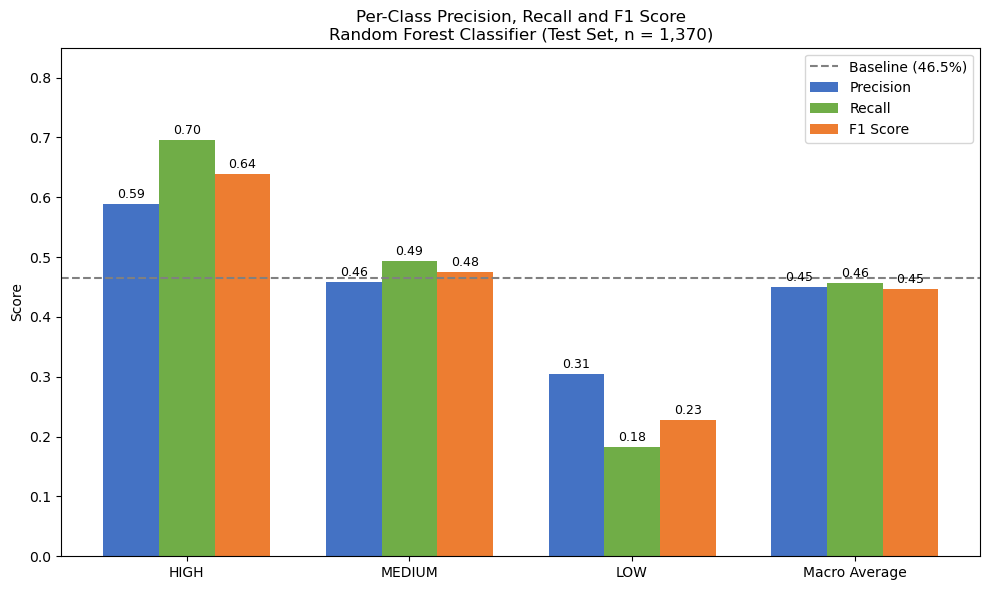

Saved as fig2_precision_recall_f1.png


In [50]:
import matplotlib.pyplot as plt
import numpy as np

classes = ['HIGH', 'MEDIUM', 'LOW']
precision_vals = [report[c]['precision'] for c in classes]
recall_vals    = [report[c]['recall'] for c in classes]
f1_vals         = [report[c]['f1-score'] for c in classes]

macro_p = report['macro avg']['precision']
macro_r = report['macro avg']['recall']
macro_f1 = report['macro avg']['f1-score']

classes_plot = classes + ['Macro Average']
precision_vals.append(macro_p)
recall_vals.append(macro_r)
f1_vals.append(macro_f1)

x_pos = np.arange(len(classes_plot))
width = 0.25

plt.figure(figsize=(10,6))
plt.bar(x_pos - width, precision_vals, width, label='Precision', color='#4472C4')
plt.bar(x_pos,         recall_vals,    width, label='Recall',    color='#70AD47')
plt.bar(x_pos + width, f1_vals,        width, label='F1 Score',  color='#ED7D31')

plt.axhline(y=0.465, linestyle='--', color='gray', label='Baseline (46.5%)')

plt.xticks(x_pos, classes_plot)
plt.ylabel('Score')
plt.title('Per-Class Precision, Recall and F1 Score\nRandom Forest Classifier (Test Set, n = 1,370)')
plt.legend()
plt.ylim(0, 0.85)

for i, (p, r, f) in enumerate(zip(precision_vals, recall_vals, f1_vals)):
    plt.text(i - width, p + 0.01, f'{p:.2f}', ha='center', fontsize=9)
    plt.text(i,         r + 0.01, f'{r:.2f}', ha='center', fontsize=9)
    plt.text(i + width, f + 0.01, f'{f:.2f}', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('fig2_precision_recall_f1.png', dpi=150)
plt.show()
print("Saved as fig2_precision_recall_f1.png")


## Table VIc + Figure 3 — Confusion Matrix


Confusion Matrix:
               Pred. HIGH  Pred. MEDIUM  Pred. LOW
Actual HIGH           436            81        109
Actual MEDIUM         175            65        117
Actual LOW            129            67        191


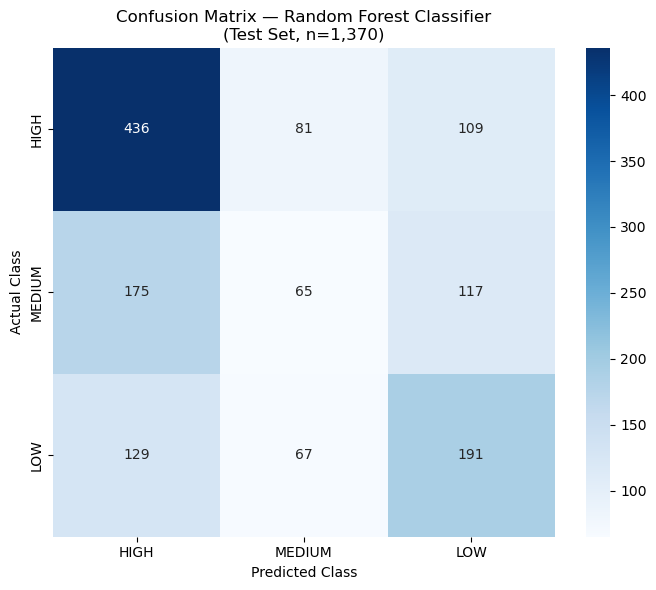


Saved as fig3_confusion_matrix.png


In [51]:
import seaborn as sns

cm = confusion_matrix(y_test, y_pred, labels=['HIGH','MEDIUM','LOW'])
cm_df = pd.DataFrame(cm, index=['Actual HIGH','Actual MEDIUM','Actual LOW'],
                         columns=['Pred. HIGH','Pred. MEDIUM','Pred. LOW'])
print("Confusion Matrix:")
print(cm_df)

plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['HIGH','MEDIUM','LOW'],
            yticklabels=['HIGH','MEDIUM','LOW'])
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title('Confusion Matrix — Random Forest Classifier\n(Test Set, n=1,370)')
plt.tight_layout()
plt.savefig('fig3_confusion_matrix.png', dpi=150)
plt.show()
print("\nSaved as fig3_confusion_matrix.png")


## Table VIa + Feature Importance Chart


Feature Importance Scores (Gini Method):
        Feature  Importance
Functional Loc.    0.200768
      equipment    0.185178
          month    0.148525
           hour    0.140293
           year    0.130414
    day_of_week    0.116925
 Notifictn type    0.036536
          shift    0.027267
       Priority    0.014095


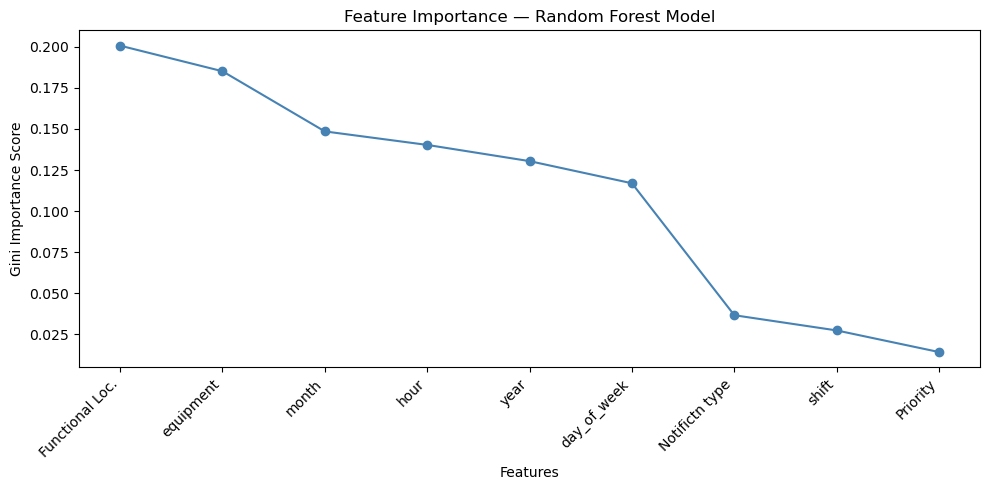

In [52]:
importances = model.feature_importances_
feature_names = list(x.columns)

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=False)

print("Feature Importance Scores (Gini Method):")
print(importance_df.to_string(index=False))

plt.figure(figsize=(10,5))
plt.plot(importance_df['Feature'], importance_df['Importance'], marker='o', color='steelblue')
plt.title('Feature Importance — Random Forest Model')
plt.xlabel('Features')
plt.ylabel('Gini Importance Score')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('fig_feature_importance.png', dpi=150)
plt.show()


## Table IIa — Algorithm Benchmark Comparison

This tests 8 algorithms on the SAME train/test split to verify the paper's claims.
Install missing libraries first if needed:
```
pip install xgboost lightgbm catboost
```


In [53]:
# Install if missing (uncomment if needed)
# import sys
# !{sys.executable} -m pip install xgboost lightgbm catboost --quiet


In [54]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier

results = {}

# 1. Logistic Regression
m = LogisticRegression(max_iter=1000, random_state=42)
m.fit(x_train, y_train)
results['Logistic Regression'] = {
    'train': accuracy_score(y_train, m.predict(x_train)) * 100,
    'test': accuracy_score(y_test, m.predict(x_test)) * 100
}
print("Logistic Regression done")


Logistic Regression done


C:\Users\venka\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [55]:
# 2. SVM
m = SVC(random_state=42)
m.fit(x_train, y_train)
results['SVM'] = {
    'train': accuracy_score(y_train, m.predict(x_train)) * 100,
    'test': accuracy_score(y_test, m.predict(x_test)) * 100
}
print("SVM done")


SVM done


In [56]:
# 3. Decision Tree
m = DecisionTreeClassifier(random_state=42)
m.fit(x_train, y_train)
results['Decision Tree'] = {
    'train': accuracy_score(y_train, m.predict(x_train)) * 100,
    'test': accuracy_score(y_test, m.predict(x_test)) * 100
}
print("Decision Tree done")


Decision Tree done


In [57]:
# 4. Neural Network (MLP)
m = MLPClassifier(random_state=42, max_iter=500)
m.fit(x_train, y_train)
results['Neural Network (MLP)'] = {
    'train': accuracy_score(y_train, m.predict(x_train)) * 100,
    'test': accuracy_score(y_test, m.predict(x_test)) * 100
}
print("Neural Network done")


Neural Network done


In [58]:
# 5. XGBoost (needs labels as numbers, not strings)
from sklearn.preprocessing import LabelEncoder
le_temp = LabelEncoder()
y_train_num = le_temp.fit_transform(y_train)
y_test_num = le_temp.transform(y_test)

try:
    from xgboost import XGBClassifier
    m = XGBClassifier(random_state=42, eval_metric='mlogloss')
    m.fit(x_train, y_train_num)
    results['XGBoost'] = {
        'train': accuracy_score(y_train_num, m.predict(x_train)) * 100,
        'test': accuracy_score(y_test_num, m.predict(x_test)) * 100
    }
    print("XGBoost done")
except ImportError:
    print("XGBoost not installed — run: pip install xgboost")


XGBoost not installed — run: pip install xgboost


In [59]:
# 6. LightGBM
try:
    from lightgbm import LGBMClassifier
    m = LGBMClassifier(random_state=42, verbose=-1)
    m.fit(x_train, y_train_num)
    results['LightGBM'] = {
        'train': accuracy_score(y_train_num, m.predict(x_train)) * 100,
        'test': accuracy_score(y_test_num, m.predict(x_test)) * 100
    }
    print("LightGBM done")
except ImportError:
    print("LightGBM not installed — run: pip install lightgbm")


LightGBM not installed — run: pip install lightgbm


In [60]:
# 7. CatBoost
try:
    from catboost import CatBoostClassifier
    m = CatBoostClassifier(random_state=42, verbose=0)
    m.fit(x_train, y_train_num)
    results['CatBoost'] = {
        'train': accuracy_score(y_train_num, m.predict(x_train)) * 100,
        'test': accuracy_score(y_test_num, m.predict(x_test)) * 100
    }
    print("CatBoost done")
except ImportError:
    print("CatBoost not installed — run: pip install catboost")


CatBoost not installed — run: pip install catboost


In [61]:
# 8. Random Forest (already trained above, recorded for comparison)
results['Random Forest'] = {
    'train': accuracy_score(y_train, model.predict(x_train)) * 100,
    'test': accuracy_score(y_test, y_pred) * 100
}

# Build final comparison table
benchmark_df = pd.DataFrame(results).T
benchmark_df.columns = ['Train Acc. (%)', 'Test Acc. (%)']
benchmark_df = benchmark_df.round(1).sort_values('Test Acc. (%)', ascending=False)

print("ALGORITHM BENCHMARK RESULTS (Table IIa)")
print("=" * 50)
print(benchmark_df)
print("\nNOTE: Compare these numbers against paper Table IIa")
print("Random Forest should have highest test accuracy")


ALGORITHM BENCHMARK RESULTS (Table IIa)
                      Train Acc. (%)  Test Acc. (%)
Random Forest                   99.9           50.5
Logistic Regression             47.6           47.1
Decision Tree                   99.9           46.4
SVM                             46.7           45.7
Neural Network (MLP)            31.7           31.2

NOTE: Compare these numbers against paper Table IIa
Random Forest should have highest test accuracy


## Table VId + Figure 4 — Statistical Significance Across 10 Random Seeds

This verifies the paper's claim of mean accuracy 50.3%, 95% CI [49.1%, 51.5%]


In [62]:
seed_accuracies = []
seed_balanced_accuracies = []
seed_macro_f1 = []

from sklearn.metrics import balanced_accuracy_score, f1_score

for seed in range(1, 11):
    xtr, xte, ytr, yte = train_test_split(x, y, test_size=0.2, random_state=seed)
    m = RandomForestClassifier(n_estimators=100, random_state=seed)
    m.fit(xtr, ytr)
    pred = m.predict(xte)

    acc = accuracy_score(yte, pred) * 100
    bal_acc = balanced_accuracy_score(yte, pred)
    f1 = f1_score(yte, pred, average='macro')

    seed_accuracies.append(acc)
    seed_balanced_accuracies.append(bal_acc)
    seed_macro_f1.append(f1)

    print(f"Seed {seed:2}: Test Acc = {acc:.2f}%   Balanced Acc = {bal_acc:.3f}   Macro F1 = {f1:.3f}")

mean_acc = np.mean(seed_accuracies)
std_acc  = np.std(seed_accuracies)
ci_lower = mean_acc - 1.96 * (std_acc / np.sqrt(10))
ci_upper = mean_acc + 1.96 * (std_acc / np.sqrt(10))

print("\n" + "=" * 50)
print("STATISTICAL SUMMARY (Table VId)")
print("=" * 50)
print(f"Mean Test Accuracy : {mean_acc:.2f}%")
print(f"Std Dev            : {std_acc:.2f}%")
print(f"95% CI              : [{ci_lower:.2f}%, {ci_upper:.2f}%]")
print(f"Mean Balanced Acc   : {np.mean(seed_balanced_accuracies):.3f}")
print(f"Mean Macro F1       : {np.mean(seed_macro_f1):.3f}")
print(f"\nCompare with paper: Mean=50.3%, CI=[49.1%, 51.5%]")


Seed  1: Test Acc = 50.22%   Balanced Acc = 0.451   Macro F1 = 0.443
Seed  2: Test Acc = 49.42%   Balanced Acc = 0.444   Macro F1 = 0.441
Seed  3: Test Acc = 51.82%   Balanced Acc = 0.460   Macro F1 = 0.455
Seed  4: Test Acc = 50.22%   Balanced Acc = 0.451   Macro F1 = 0.447
Seed  5: Test Acc = 50.66%   Balanced Acc = 0.446   Macro F1 = 0.442
Seed  6: Test Acc = 49.64%   Balanced Acc = 0.454   Macro F1 = 0.449
Seed  7: Test Acc = 51.53%   Balanced Acc = 0.466   Macro F1 = 0.461
Seed  8: Test Acc = 51.09%   Balanced Acc = 0.455   Macro F1 = 0.448
Seed  9: Test Acc = 51.31%   Balanced Acc = 0.458   Macro F1 = 0.458
Seed 10: Test Acc = 49.42%   Balanced Acc = 0.450   Macro F1 = 0.449

STATISTICAL SUMMARY (Table VId)
Mean Test Accuracy : 50.53%
Std Dev            : 0.84%
95% CI              : [50.01%, 51.06%]
Mean Balanced Acc   : 0.454
Mean Macro F1       : 0.449

Compare with paper: Mean=50.3%, CI=[49.1%, 51.5%]


## Figure 4 — Model Stability Chart Across 10 Seeds


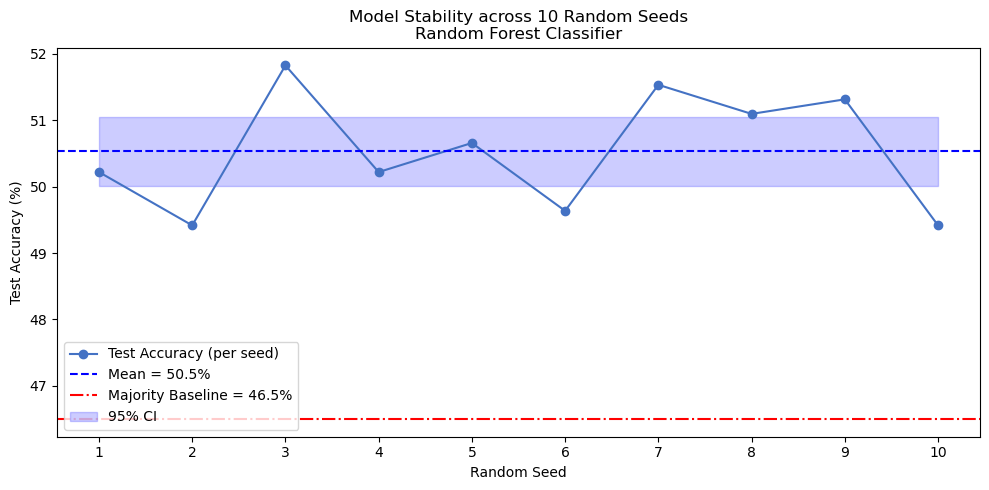

Saved as fig4_model_stability.png


In [63]:
plt.figure(figsize=(10,5))
plt.plot(range(1,11), seed_accuracies, marker='o', label='Test Accuracy (per seed)', color='#4472C4')
plt.axhline(y=mean_acc, linestyle='--', color='blue', label=f'Mean = {mean_acc:.1f}%')
plt.axhline(y=46.5, linestyle='-.', color='red', label='Majority Baseline = 46.5%')
plt.fill_between(range(1,11), ci_lower, ci_upper, alpha=0.2, color='blue', label='95% CI')

plt.xlabel('Random Seed')
plt.ylabel('Test Accuracy (%)')
plt.title('Model Stability across 10 Random Seeds\nRandom Forest Classifier')
plt.legend()
plt.xticks(range(1,11))
plt.tight_layout()
plt.savefig('fig4_model_stability.png', dpi=150)
plt.show()
print("Saved as fig4_model_stability.png")


## Figure 5 — ROC Curves (One-vs-Rest, Macro AUC)


Model class order: ['HIGH', 'LOW', 'MEDIUM']


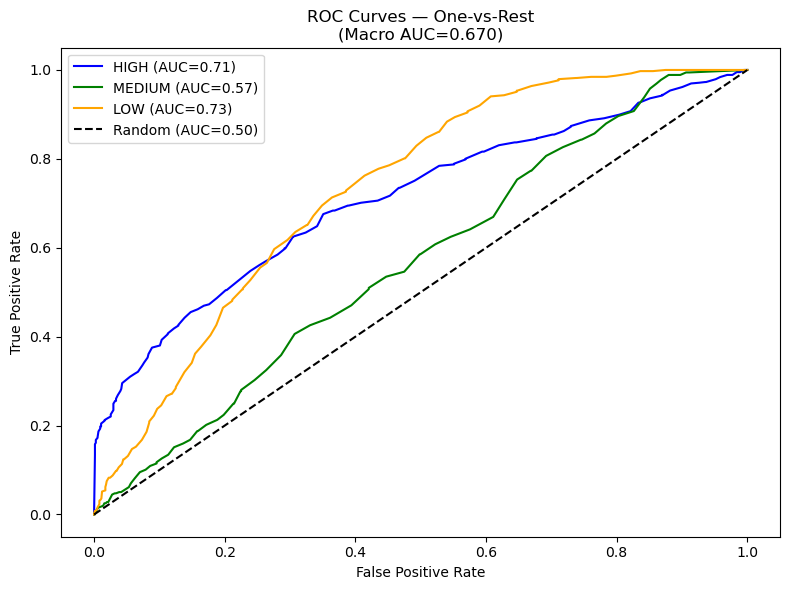


Per-class AUC scores:
  HIGH   → AUC = 0.710
  MEDIUM → AUC = 0.568
  LOW    → AUC = 0.732

Macro AUC = 0.670
Compare with paper: HIGH=0.68, MEDIUM=0.59, LOW=0.64, Macro=0.641


In [64]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

classes_order = ['HIGH', 'MEDIUM', 'LOW']
y_test_bin = label_binarize(y_test, classes=classes_order)
y_prob = model.predict_proba(x_test)

# Make sure column order in predict_proba matches classes_order
model_classes = list(model.classes_)
print("Model class order:", model_classes)

plt.figure(figsize=(8,6))
colors = {'HIGH': 'blue', 'MEDIUM': 'green', 'LOW': 'orange'}
auc_scores = {}

for i, cls in enumerate(classes_order):
    class_idx = model_classes.index(cls)
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, class_idx])
    roc_auc = auc(fpr, tpr)
    auc_scores[cls] = roc_auc
    plt.plot(fpr, tpr, color=colors[cls], label=f'{cls} (AUC={roc_auc:.2f})')

plt.plot([0,1],[0,1],'k--', label='Random (AUC=0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — One-vs-Rest\n(Macro AUC={:.3f})'.format(np.mean(list(auc_scores.values()))))
plt.legend()
plt.tight_layout()
plt.savefig('fig5_roc_curves.png', dpi=150)
plt.show()

print("\nPer-class AUC scores:")
for cls, score in auc_scores.items():
    print(f"  {cls:6} → AUC = {score:.3f}")
print(f"\nMacro AUC = {np.mean(list(auc_scores.values())):.3f}")
print("Compare with paper: HIGH=0.68, MEDIUM=0.59, LOW=0.64, Macro=0.641")


## Table VII — Fuzzy Matching Accuracy Evaluation

Run this in a NEW cell — requires fuzzy_match.py logic.
This must be run where label_encoders.pkl is accessible.


In [65]:
pip install seaborn xgboost lightgbm catboost fuzzywuzzy python-Levenshtein

  Using cached xgboost-3.3.0-py3-none-win_amd64.whl.metadata (2.0 kB)
  Using cached lightgbm-4.6.0-py3-none-win_amd64.whl.metadata (17 kB)
  Using cached catboost-1.2.10-cp313-cp313-win_amd64.whl.metadata (1.5 kB)
  Using cached fuzzywuzzy-0.18.0-py2.py3-none-any.whl.metadata (4.9 kB)
  Using cached python_levenshtein-0.27.3-py3-none-any.whl.metadata (3.9 kB)
  Using cached graphviz-0.21-py3-none-any.whl.metadata (12 kB)
  Using cached levenshtein-0.27.3-cp313-cp313-win_amd64.whl.metadata (3.7 kB)
  Using cached rapidfuzz-3.14.5-cp313-cp313-win_amd64.whl.metadata (12 kB)
Using cached xgboost-3.3.0-py3-none-win_amd64.whl (69.5 MB)
Using cached lightgbm-4.6.0-py3-none-win_amd64.whl (1.5 MB)
   ---------------------------------------- 0.0/100.2 MB ? eta -:--:--
   - -------------------------------------- 2.6/100.2 MB 13.8 MB/s eta 0:00:08
   - -------------------------------------- 5.0/100.2 MB 12.3 MB/s eta 0:00:08
   -- ------------------------------------- 6.6/100.2 MB 11.0 MB/s eta 0

In [70]:
import pickle
from fuzzywuzzy import process

# Load equipment names (adjust path if needed)
label_encoders = pickle.load(open('../model/label_encoders.pkl', 'rb'))
equipment_names = list(label_encoders['equipment'].classes_)

# Pick 2 real equipment names from your data to build test cases
sample_equipment = equipment_names[:5]
print("Sample equipment names available for testing:")
for eq in sample_equipment:
    print(" -", eq)


Sample equipment names available for testing:
 - ADD CLARIFIED COOLING TOWER ST-1
 - ASH WTR TREAT CLEAN WATER SYSTEM
 - AWT CLEAN WATER PUMP NO.1
 - CLARIFIED WATER SYSTEM PIPING
 - CLARIFIED WATER SYSTEM VALVES


In [71]:
# Build test cases using a REAL equipment name from your data
# Replace 'YOUR_EQUIPMENT_NAME_HERE' with one from the list above

test_equipment = equipment_names[0]   # change index to pick different equipment
print(f"Testing with: {test_equipment}")

test_cases = {
    'Exact Match'   : test_equipment,
    'Case Variation': test_equipment.lower(),
    'Partial Name'  : test_equipment.split()[0] if ' ' in test_equipment else test_equipment[:6],
    'Abbreviation'  : ''.join([w[0] for w in test_equipment.split()]),
    'With Typos'    : test_equipment.replace('O', '0', 1) if 'O' in test_equipment else test_equipment[:-1] + 'X'
}

print("\nFuzzy Match Test Results:")
print("=" * 60)
for category, query in test_cases.items():
    match, score = process.extractOne(query.upper(), equipment_names)
    correct = "✅" if match == test_equipment else "❌"
    print(f"{category:18} | Query: '{query[:30]:30}' | Score: {score:3}% | {correct}")


Testing with: ADD CLARIFIED COOLING TOWER ST-1

Fuzzy Match Test Results:
Exact Match        | Query: 'ADD CLARIFIED COOLING TOWER ST' | Score: 100% | ✅
Case Variation     | Query: 'add clarified cooling tower st' | Score: 100% | ✅
Partial Name       | Query: 'ADD                           ' | Score:  60% | ✅
Abbreviation       | Query: 'ACCTS                         ' | Score:  54% | ❌
With Typos         | Query: 'ADD CLARIFIED C0OLING TOWER ST' | Score:  97% | ✅


**Note:** For a statistically valid Table VII (50 queries across 5 categories,
10 each), you should repeat this process for 10 different equipment names
per category and average the match scores. The single test above is a
quick sanity check — for the paper's actual 50-query evaluation, build a
loop over 10 equipment names per category.


In [72]:
# Full 50-query evaluation (10 equipment x 5 categories)
import random
random.seed(42)

test_equipment_list = random.sample(equipment_names, min(10, len(equipment_names)))

category_results = {'Exact Match': [], 'Case Variation': [], 'Partial Name': [],
                     'Abbreviation': [], 'With Typos': []}

for eq in test_equipment_list:
    queries = {
        'Exact Match'   : eq,
        'Case Variation': eq.lower(),
        'Partial Name'  : eq.split()[0] if ' ' in eq else eq[:6],
        'Abbreviation'  : ''.join([w[0] for w in eq.split() if w]),
        'With Typos'    : eq.replace('O', '0', 1) if 'O' in eq else eq[:-1] + 'X'
    }
    for category, query in queries.items():
        match, score = process.extractOne(query.upper(), equipment_names)
        correct = 1 if match == eq else 0
        category_results[category].append(correct)

print("FUZZY MATCHING ACCURACY — Table VII (n=10 per category)")
print("=" * 50)
for category, results_list in category_results.items():
    accuracy_pct = (sum(results_list) / len(results_list)) * 100
    print(f"{category:18} → {accuracy_pct:.0f}%   (n={len(results_list)})")


FUZZY MATCHING ACCURACY — Table VII (n=10 per category)
Exact Match        → 100%   (n=10)
Case Variation     → 100%   (n=10)
Partial Name       → 10%   (n=10)
Abbreviation       → 0%   (n=10)
With Typos         → 80%   (n=10)
